## Bài 2: Huấn luyện, Kiểm định chéo 5-Fold, Khảo sát ngưỡng và Tinh chỉnh siêu tham số

- Đối chiếu 5 cấu hình: `DummyClassifier`, `Perceptron` (PLA), `SGDClassifier(loss='log_loss')`, `LogisticRegression` (Mặc định & Balanced).
- Báo cáo kiểm định chéo phân tầng **5-Fold (`Mean ± Std`)** trên Tập Train ($N = 35.000$).
- Khảo sát ngưỡng xác suất **Out-of-Fold (`cross_val_predict`)** và tinh chỉnh siêu tham số trên **Tập Validation** ($N = 7.500$).

### 1. Khởi tạo bộ dữ liệu 70/15/15 và Đóng gói 5 Pipeline mô hình

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Perceptron, SGDClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    log_loss,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")

# Đồng bộ giao diện và bảng màu với Kiemtra1
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
PALETTE_4 = ["#2ecc71", "#3498db", "#e74c3c", "#f39c12"]

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

DATA_PATH = Path("../data/Loan_approval_data_2025.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/Loan_approval_data_2025.csv")
assert DATA_PATH.exists(), f"Không tìm thấy dữ liệu tại {DATA_PATH.resolve()}"

IMG_DIR = Path("../images")
MODEL_DIR = Path("../models")
IMG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)


def get_model_score(estimator, X_eval):
    '''Trích xuất điểm liên tục (xác suất lớp 1 hoặc khoảng cách decision_function).'''
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X_eval)[:, 1]
    return estimator.decision_function(X_eval)


def evaluate(y_true, y_pred, y_score):
    '''Tính bộ chỉ số đánh giá đa chiều cho bài toán phân loại tín dụng.'''
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "F1-Macro": f1_score(y_true, y_pred, average="macro"),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        "PR-AUC": average_precision_score(y_true, y_score),
    }


def load_and_split_data():
    '''Nạp dữ liệu, loại bỏ customer_id và chia phân tầng 70% Train / 15% Val / 15% Test.'''
    df = pd.read_csv(DATA_PATH)
    X = df.drop(columns=["customer_id", "loan_status"])
    y = df["loan_status"]

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=RANDOM_SEED
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_SEED
    )

    cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
    num_cols = [c for c in X.columns if c not in cat_cols]
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            (
                "cat",
                OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"),
                cat_cols,
            ),
        ],
        remainder="drop",
    )
    return df, X, y, X_train, X_val, X_test, y_train, y_val, y_test, num_cols, cat_cols, preprocessor


def build_pipelines(preprocessor):
    '''Đóng gói mô hình cơ sở và các thuật toán Bài 4 & Bài 5 vào Pipeline thống nhất.'''
    models = {
        "Dummy (Baseline đa số)": DummyClassifier(strategy="most_frequent"),
        "Perceptron (PLA)": Perceptron(max_iter=1000, tol=1e-3, random_state=RANDOM_SEED),
        "SGDClassifier (Log-loss + GD)": SGDClassifier(
            loss="log_loss",
            penalty="l2",
            alpha=1e-4,
            max_iter=1000,
            tol=1e-4,
            random_state=RANDOM_SEED,
        ),
        "Logistic Regression (Mặc định)": LogisticRegression(
            max_iter=1000, C=1.0, random_state=RANDOM_SEED
        ),
        "Logistic Regression (Balanced)": LogisticRegression(
            max_iter=1000, C=1.0, class_weight="balanced", random_state=RANDOM_SEED
        ),
    }
    return {
        name: Pipeline([("preprocessor", preprocessor), ("classifier", clf)])
        for name, clf in models.items()
    }

df, X, y, X_train, X_val, X_test, y_train, y_val, y_test, num_cols, cat_cols, preprocessor = load_and_split_data()
pipelines = build_pipelines(preprocessor)

print("Đã sẵn sàng", len(pipelines), "Pipeline trên Tập Train:", X_train.shape)
for idx, name in enumerate(pipelines, start=1):
    print(f" {idx}. {name}")

Đã sẵn sàng 5 Pipeline trên Tập Train: (35000, 18)
 1. Dummy (Baseline đa số)
 2. Perceptron (PLA)
 3. SGDClassifier (Log-loss + GD)
 4. Logistic Regression (Mặc định)
 5. Logistic Regression (Balanced)


### 2. Kiểm định chéo phân tầng 5-Fold trên Tập Huấn luyện ($N = 35.000$)

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
scoring_metrics = {
    "roc_auc": "roc_auc",
    "f1_macro": "f1_macro",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
}

cv_rows = []
for name, pipe in pipelines.items():
    t0 = time.perf_counter()
    res = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring_metrics,
        return_train_score=True,
        n_jobs=-1,
    )
    elapsed = time.perf_counter() - t0
    cv_rows.append(
        {
            "Mô hình": name,
            "ROC-AUC (Mean)": res["test_roc_auc"].mean(),
            "ROC-AUC (Std)": res["test_roc_auc"].std(),
            "F1-Macro (Mean)": res["test_f1_macro"].mean(),
            "F1-Macro (Std)": res["test_f1_macro"].std(),
            "Accuracy (Mean)": res["test_accuracy"].mean(),
            "Precision (Mean)": res["test_precision"].mean(),
            "Precision (Std)": res["test_precision"].std(),
            "Recall (Mean)": res["test_recall"].mean(),
            "Recall (Std)": res["test_recall"].std(),
            "Thời gian CV (s)": elapsed,
        }
    )

cv_df = pd.DataFrame(cv_rows)
cv_display = pd.DataFrame({"Mô hình": cv_df["Mô hình"]})
for m, col_label in [
    ("ROC-AUC", "ROC-AUC (CV)"),
    ("F1-Macro", "F1-Macro (CV)"),
    ("Precision", "Precision (CV)"),
    ("Recall", "Recall (CV)"),
]:
    cv_display[col_label] = cv_df.apply(
        lambda r: f"{r[f'{m} (Mean)']:.4f} ± {r[f'{m} (Std)']:.4f}", axis=1
    )
cv_display["Accuracy (CV)"] = cv_df["Accuracy (Mean)"].map(lambda v: f"{v:.4f}")
cv_display["Thời gian (s)"] = cv_df["Thời gian CV (s)"].map(lambda v: f"{v:.2f}")

print("=" * 80)
print("BẢNG SO SÁNH KIỂM ĐỊNH CHÉO 5-FOLD (MEAN ± STD)")
print("=" * 80)
display(cv_display)

BẢNG SO SÁNH KIỂM ĐỊNH CHÉO 5-FOLD (MEAN ± STD)


,Mô hình,ROC-AUC (CV),F1-Macro (CV),Precision (CV),Recall (CV),Accuracy (CV),Thời gian (s)
0,Dummy (Baseline đa số),0.5000 ± 0.0000,0.3550 ± 0.0000,0.5505 ± 0.0001,1.0000 ± 0.0000,0.5505,4.00
1,Perceptron (PLA),0.9136 ± 0.0115,0.8229 ± 0.0091,0.8530 ± 0.0336,0.8281 ± 0.0492,0.8248,3.11
2,SGDClassifier (Log-loss + GD),0.9448 ± 0.0018,0.8642 ± 0.0015,0.8715 ± 0.0035,0.8872 ± 0.0076,0.8659,2.58
3,Logistic Regression (Mặc định),0.9457 ± 0.0024,0.8651 ± 0.0028,0.8724 ± 0.0030,0.8878 ± 0.0036,0.8667,0.44
4,Logistic Regression (Balanced),0.9457 ± 0.0023,0.8640 ± 0.0034,0.8846 ± 0.0032,0.8682 ± 0.0034,0.8651,0.43


- **So với Baseline:** `Perceptron` (PLA) nâng ROC-AUC lên $0{,}9136 \pm 0{,}0115$ nhưng F1-Macro mới đạt $0{,}8229 \pm 0{,}0091$ kèm độ lệch chuẩn Precision/Recall lớn ($\pm 0{,}0336$ / $\pm 0{,}0492$).
- **Ưu thế tối ưu Log-loss:** `Logistic Regression (Mặc định)` dẫn đầu với `ROC-AUC = 0,9457 ± 0,0024` và `F1-Macro = 0,8651 ± 0,0028` chỉ trong $\approx 0{,}5$ giây; `SGDClassifier (Log-loss + GD)` đạt kết quả tương đương (`0,9448 ± 0,0018` AUC).

### 3. Biểu đồ so sánh Kiểm định chéo 5-Fold giữa 5 mô hình (`Mean ± Std`)

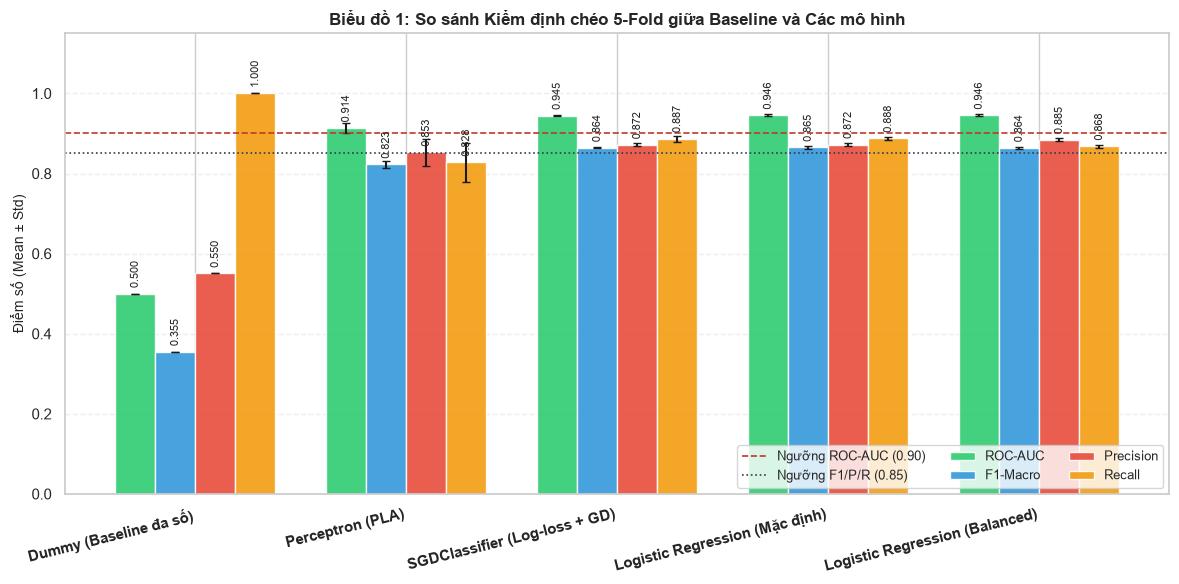

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))
plot_metrics = ["ROC-AUC", "F1-Macro", "Precision", "Recall"]
x = np.arange(len(cv_df))
width = 0.19

for i, (m, col) in enumerate(zip(plot_metrics, PALETTE_4)):
    means = cv_df[f"{m} (Mean)"].values
    stds = cv_df[f"{m} (Std)"].values
    bars = ax.bar(
        x + (i - 1.5) * width,
        means,
        width,
        yerr=stds,
        capsize=3,
        label=m,
        color=col,
        alpha=0.9,
        edgecolor="white",
    )
    for bar, val in zip(bars, means):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val + 0.014,
            f"{val:.3f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90,
        )

ax.axhline(0.90, color="#c0392b", linestyle="--", linewidth=1.2, label="Ngưỡng ROC-AUC (0.90)")
ax.axhline(0.85, color="#2c3e50", linestyle=":", linewidth=1.2, label="Ngưỡng F1/P/R (0.85)")
ax.set_xticks(x)
ax.set_xticklabels(cv_df["Mô hình"], rotation=14, ha="right", fontweight="bold")
ax.set_ylim(0.0, 1.15)
ax.set_ylabel("Điểm số (Mean ± Std)")
ax.set_title("Biểu đồ 1: So sánh Kiểm định chéo 5-Fold giữa Baseline và Các mô hình", fontweight="bold")
ax.legend(loc="lower right", ncol=3, fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.savefig(IMG_DIR / "bieu_do_so_sanh_mo_hinh.png", dpi=90)
plt.show()

- **Vượt chuẩn cam kết:** Ba cấu hình tối ưu theo Log-loss (`SGDClassifier`, `Logistic Regression Mặc định` và `Balanced`) đều vượt dứt khoát hai ngưỡng mục tiêu `0,90` (ROC-AUC) và `0,85` (F1-Macro, Precision, Recall) với thanh sai số $\pm \sigma$ rất hẹp.
- **Đánh đổi Balanced:** Bật `class_weight='balanced'` đẩy Precision lớp duyệt lên $0{,}8846$ (lọc nợ xấu chặt hơn), đổi lại Recall giảm nhẹ từ $0{,}8878$ xuống $0{,}8682$.

### 4. Khảo sát ngưỡng xác suất Out-of-Fold (`cross_val_predict`) và Kiểm chứng Tập Validation ($N = 7.500$)

In [4]:
fitted_pipelines = {}
val_rows = []
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    y_val_pred = pipe.predict(X_val)
    y_val_score = get_model_score(pipe, X_val)
    val_rows.append({"Mô hình": name, **evaluate(y_val, y_val_pred, y_val_score)})

val_df = pd.DataFrame(val_rows)
print("=" * 80)
print("KẾT QUẢ TRÊN TẬP VALIDATION (N = 7.500)")
print("=" * 80)
display(val_df.round(4))

oof_probs = cross_val_predict(
    pipelines["Logistic Regression (Mặc định)"],
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]
val_probs = fitted_pipelines["Logistic Regression (Mặc định)"].predict_proba(X_val)[:, 1]

thr_rows = []
for thr in [0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65]:
    oof_pred = (oof_probs >= thr).astype(int)
    val_pred = (val_probs >= thr).astype(int)
    tn_o, fp_o, _, _ = confusion_matrix(y_train, oof_pred).ravel()
    _, fp_v, fn_v, _ = confusion_matrix(y_val, val_pred).ravel()
    thr_rows.append(
        {
            "Ngưỡng (tau)": thr,
            "OOF F1-Macro": round(f1_score(y_train, oof_pred, average="macro"), 4),
            "OOF Precision": round(precision_score(y_train, oof_pred), 4),
            "OOF Recall": round(recall_score(y_train, oof_pred), 4),
            "OOF Specificity": round(tn_o / (tn_o + fp_o), 4),
            "Val F1-Macro": round(f1_score(y_val, val_pred, average="macro"), 4),
            "Val FP (Duyệt nhầm xấu)": int(fp_v),
            "Val FN (Từ chối nhầm tốt)": int(fn_v),
        }
    )

print("-" * 80)
print("KHẢO SÁT NGƯỠNG PHÂN LOẠI TRÊN OUT-OF-FOLD & VALIDATION")
print("-" * 80)
display(pd.DataFrame(thr_rows))

KẾT QUẢ TRÊN TẬP VALIDATION (N = 7.500)


,Mô hình,ROC-AUC,F1-Macro,Accuracy,Precision,Recall,Specificity,PR-AUC
0,Dummy (Baseline đa số),0.5000,0.3551,0.5505,0.5505,1.0000,0.0000,0.5505
1,Perceptron (PLA),0.9060,0.8127,0.8128,0.8805,0.7636,0.8730,0.9097
2,SGDClassifier (Log-loss + GD),0.9466,0.8659,0.8673,0.8787,0.8806,0.8511,0.9554
3,Logistic Regression (Mặc định),0.9478,0.8688,0.8703,0.8791,0.8862,0.8508,0.9562
4,Logistic Regression (Balanced),0.9478,0.8642,0.8652,0.8876,0.8646,0.8659,0.9562


--------------------------------------------------------------------------------
KHẢO SÁT NGƯỠNG PHÂN LOẠI TRÊN OUT-OF-FOLD & VALIDATION
--------------------------------------------------------------------------------


,Ngưỡng (tau),OOF F1-Macro,OOF Precision,OOF Recall,OOF Specificity,Val F1-Macro,Val FP (Duyệt nhầm xấu),Val FN (Từ chối nhầm tốt)
0,0.35,0.8565,0.8304,0.9388,0.7653,0.8608,764,250
1,0.40,0.8620,0.8462,0.9227,0.7946,0.8660,665,318
2,0.45,0.8649,0.8602,0.9061,0.8196,0.8689,575,393
3,0.50,0.8651,0.8723,0.8878,0.8409,0.8688,503,470
4,0.55,0.8642,0.8848,0.8684,0.8616,0.8645,450,559
5,0.60,0.8602,0.8968,0.8444,0.8810,0.8616,393,640
6,0.65,0.8547,0.9084,0.8192,0.8988,0.8558,340,739


- **Ngưỡng cân bằng:** Tại $\tau = 0{,}50$, OOF F1-Macro đạt cực đại ($0{,}8651$), tương ứng trên Validation là $0{,}8688$ ($503$ FP và $470$ FN).
- **Điều chỉnh khẩu vị rủi ro:** Khi nâng ngưỡng phê duyệt lên $\tau = 0{,}60$, OOF Precision tăng lên $0{,}8968$ (Specificity $0{,}8810$) và số ca duyệt nhầm nợ xấu (FP) trên Validation giảm $21{,}9\%$ (từ $503$ xuống chỉ còn $393$ hồ sơ).

### 5. Tinh chỉnh siêu tham số ($C$, $\alpha$, `learning_rate`) trên Tập Validation

In [5]:
tuning_configs = [
    ("LogisticRegression (C=0.01)", LogisticRegression(C=0.01, max_iter=1000, random_state=RANDOM_SEED)),
    ("LogisticRegression (C=0.1)", LogisticRegression(C=0.1, max_iter=1000, random_state=RANDOM_SEED)),
    ("LogisticRegression (C=1.0, mặc định)", LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_SEED)),
    ("LogisticRegression (C=10.0)", LogisticRegression(C=10.0, max_iter=1000, random_state=RANDOM_SEED)),
    ("SGDClassifier (alpha=1e-2, optimal)", SGDClassifier(loss="log_loss", alpha=1e-2, max_iter=1000, tol=1e-4, random_state=RANDOM_SEED)),
    ("SGDClassifier (alpha=1e-4, optimal)", SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=1000, tol=1e-4, random_state=RANDOM_SEED)),
    ("SGDClassifier (alpha=1e-4, constant, eta0=0.01)", SGDClassifier(loss="log_loss", alpha=1e-4, learning_rate="constant", eta0=0.01, max_iter=1000, tol=1e-4, random_state=RANDOM_SEED)),
]

tuning_rows = []
for cfg_name, clf in tuning_configs:
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", clf)])
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_sec = time.perf_counter() - t0

    tr_auc = roc_auc_score(y_train, get_model_score(pipe, X_train))
    va_score = get_model_score(pipe, X_val)
    va_pred = pipe.predict(X_val)
    tuning_rows.append(
        {
            "Cấu hình": cfg_name,
            "Train AUC": tr_auc,
            "Val AUC": roc_auc_score(y_val, va_score),
            "Val F1-Macro": f1_score(y_val, va_pred, average="macro"),
            "Chênh lệch AUC": tr_auc - roc_auc_score(y_val, va_score),
            "Thời gian fit (s)": fit_sec,
        }
    )

print("=" * 80)
print("TINH CHỈNH SIÊU THAM SỐ TRÊN TẬP VALIDATION (KHÔNG CHẠM TEST)")
print("=" * 80)
display(pd.DataFrame(tuning_rows).round(4))

TINH CHỈNH SIÊU THAM SỐ TRÊN TẬP VALIDATION (KHÔNG CHẠM TEST)


,Cấu hình,Train AUC,Val AUC,Val F1-Macro,Chênh lệch AUC,Thời gian fit (s)
0,LogisticRegression (C=0.01),0.9420,0.9452,0.8662,-0.0032,0.0814
1,LogisticRegression (C=0.1),0.9454,0.9477,0.8701,-0.0023,0.0839
2,"LogisticRegression (C=1.0, mặc định)",0.9459,0.9478,0.8688,-0.0019,0.0926
3,LogisticRegression (C=10.0),0.9459,0.9477,0.8685,-0.0018,0.0904
4,"SGDClassifier (alpha=1e-2, optimal)",0.9382,0.9418,0.8618,-0.0036,0.0953
5,"SGDClassifier (alpha=1e-4, optimal)",0.9451,0.9466,0.8659,-0.0014,0.2640
6,"SGDClassifier (alpha=1e-4, constant, eta0=0.01)",0.9447,0.9465,0.8678,-0.0017,0.1170


- **Hệ số $C$ của `LogisticRegression`:** $C = 1{,}0$ đạt đỉnh Val ROC-AUC ($0{,}9478$) trong $\approx 0{,}09$ giây (chênh lệch Train–Val chỉ $0{,}0019$), còn $C = 0{,}1$ đạt Val F1-Macro cao nhất ($0{,}8701$).
- **Hệ số $\alpha$ và `learning_rate` của `SGDClassifier`:** Phạt quá mạnh ($\alpha = 10^{-2}$) kéo Val AUC xuống $0{,}9418$, trong khi $\alpha = 10^{-4}$ khôi phục Val AUC lên $0{,}9466$ (và `constant`, `eta0=0.01` đạt F1-Macro $0{,}8678$ sau $0{,}12$ giây).